# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import AirbusWindTurbinesDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/wind_turbines/train/",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = AirbusWindTurbinesDataset(dataset_config)

## Show images from the dataset

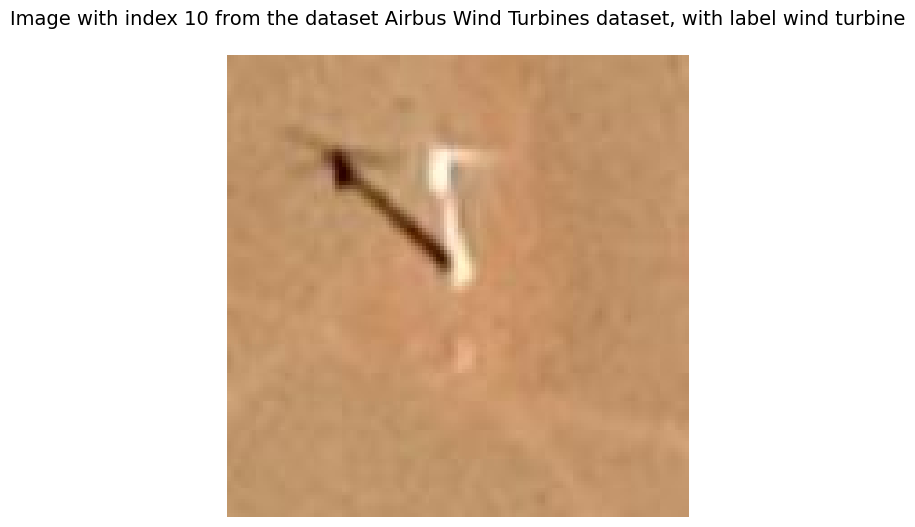

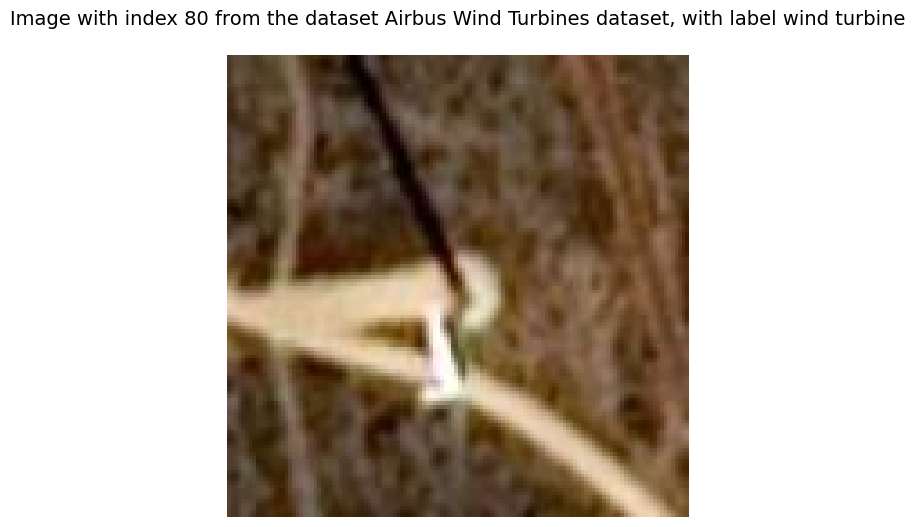

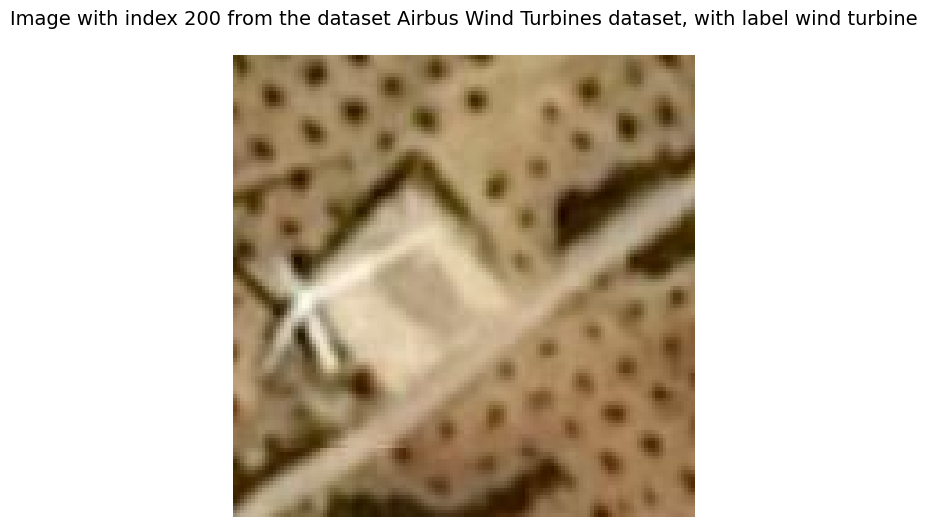

In [14]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

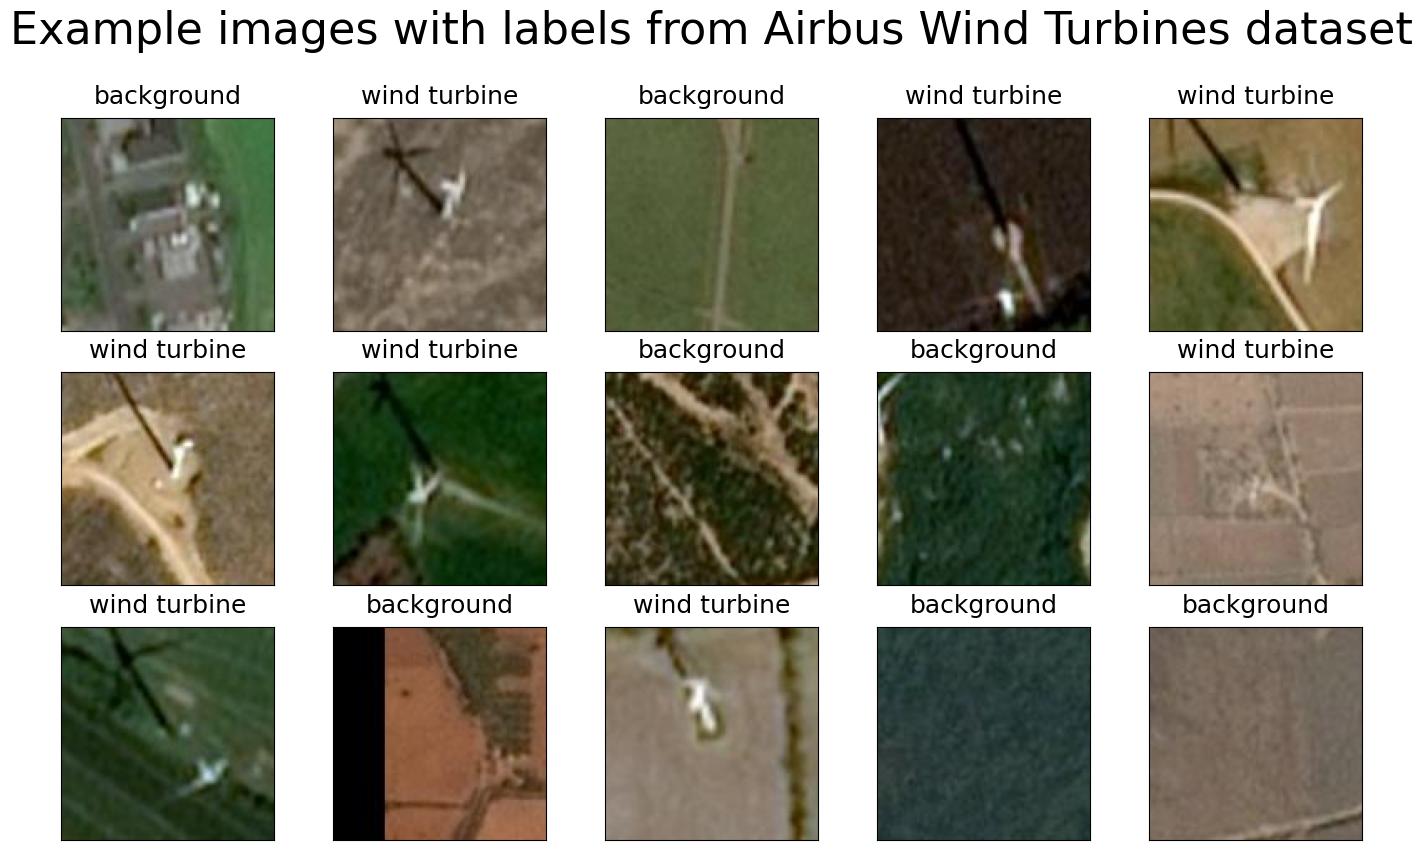

In [18]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [19]:
dataset.data_distribution_table()

,Label,Count
0,background,202565
1,wind turbine,154942


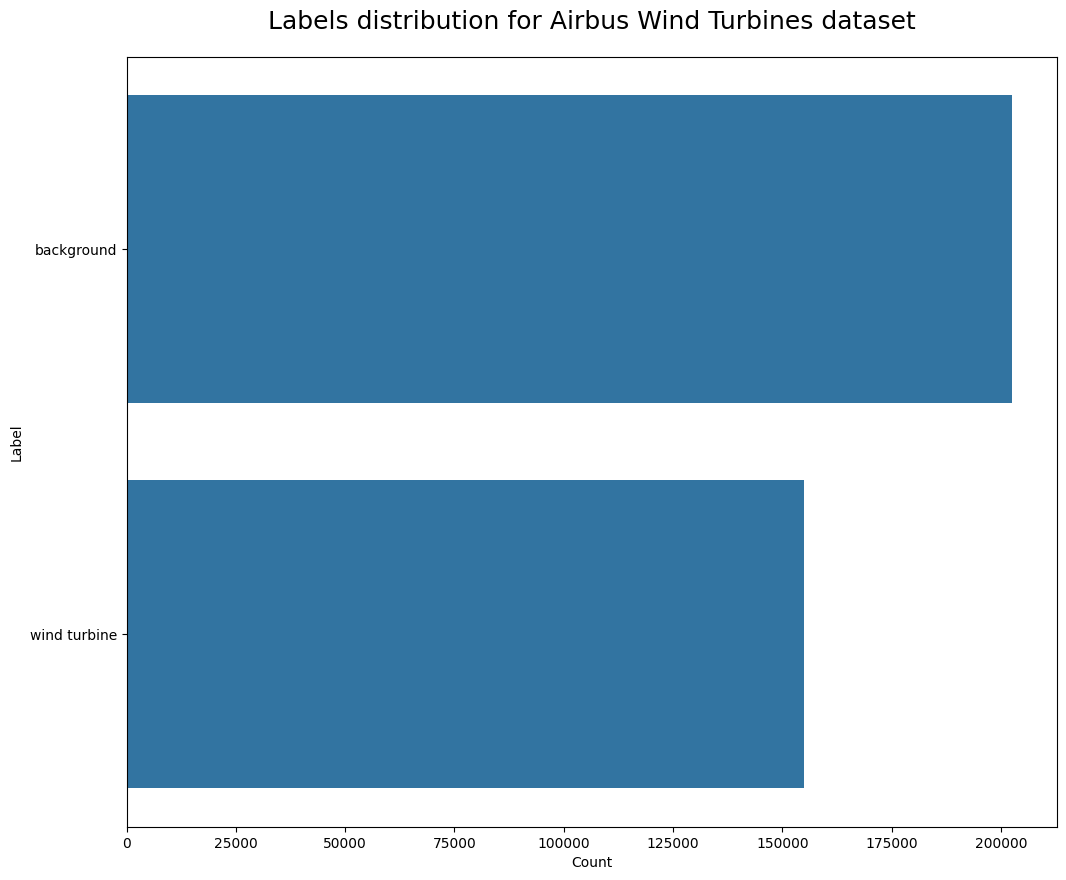

In [20]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/wind_turbines/train/",
}

train_dataset = AirbusWindTurbinesDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/wind_turbines/val/",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = AirbusWindTurbinesDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(357507, 71504)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/wind_turbines/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-21 06:44:14,540 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-21 06:44:14,726 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [6]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-21 06:44:16,195 INFO Starting training.
training: 100%|██████████| 11173/11173 [2:09:42<00:00,  1.44it/s]
2025-05-21 08:53:59,150 INFO epoch: 1, time: 7783, loss:  0.03364
testing on train set: 100%|██████████| 11173/11173 [55:41<00:00,  3.34it/s]
2025-05-21 09:49:42,741 INFO Accuracy:0.9932364960686084, Precision Micro:0.9932364960686084, Precision Macro:0.992942405194888, Precision Weighted:0.993242494965392, Precision per Class:[0.99519519 0.99068962], Recall Micro:0.9932364960686084, Recall Macro:0.9932948763891758, Recall Weighted:0.9932364960686084, Recall per Class:[0.99285661 0.99373314], F1_score Micro:0.9932364960686079, F1_score Macro:0.9931167861066528, F1_score Weighted:0.9932377046702558, F1_score per Class:[0.99402452 0.99220905]
testing on validation set: 100%|██████████| 2235/2235 [11:22<00:00,  3.28it/s]
2025-05-21 10:01:04,778 INFO Accuracy:0.9939863504139629, Precision Micro:0.9939863504139629, Precision Macro:0.9935819587239443, Precision Weighted:0.9940009

0.018202856337628456

## Predictions

2025-05-22 07:07:52,497 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/wind_turbines/checkpoint.pth.tar
2025-05-22 07:07:52,794 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/wind_turbines/checkpoint.pth.tar at epoch 11


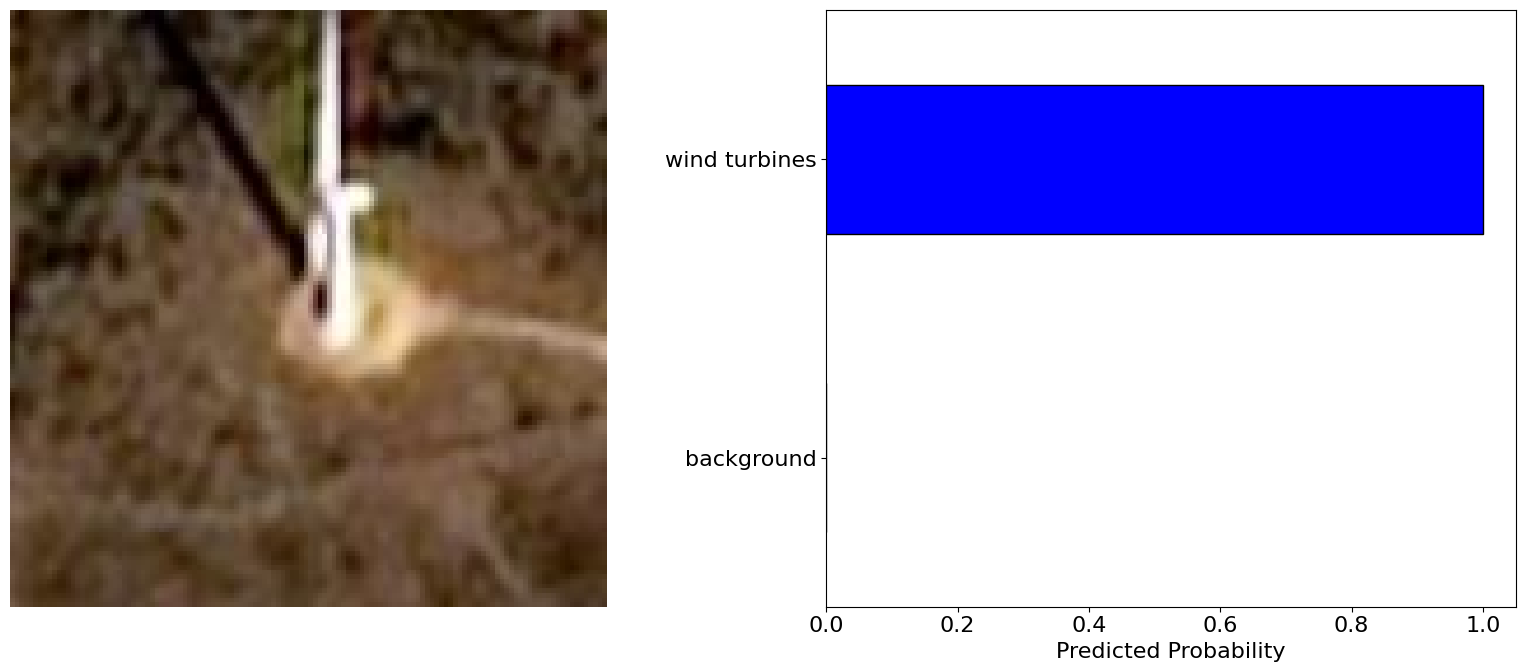

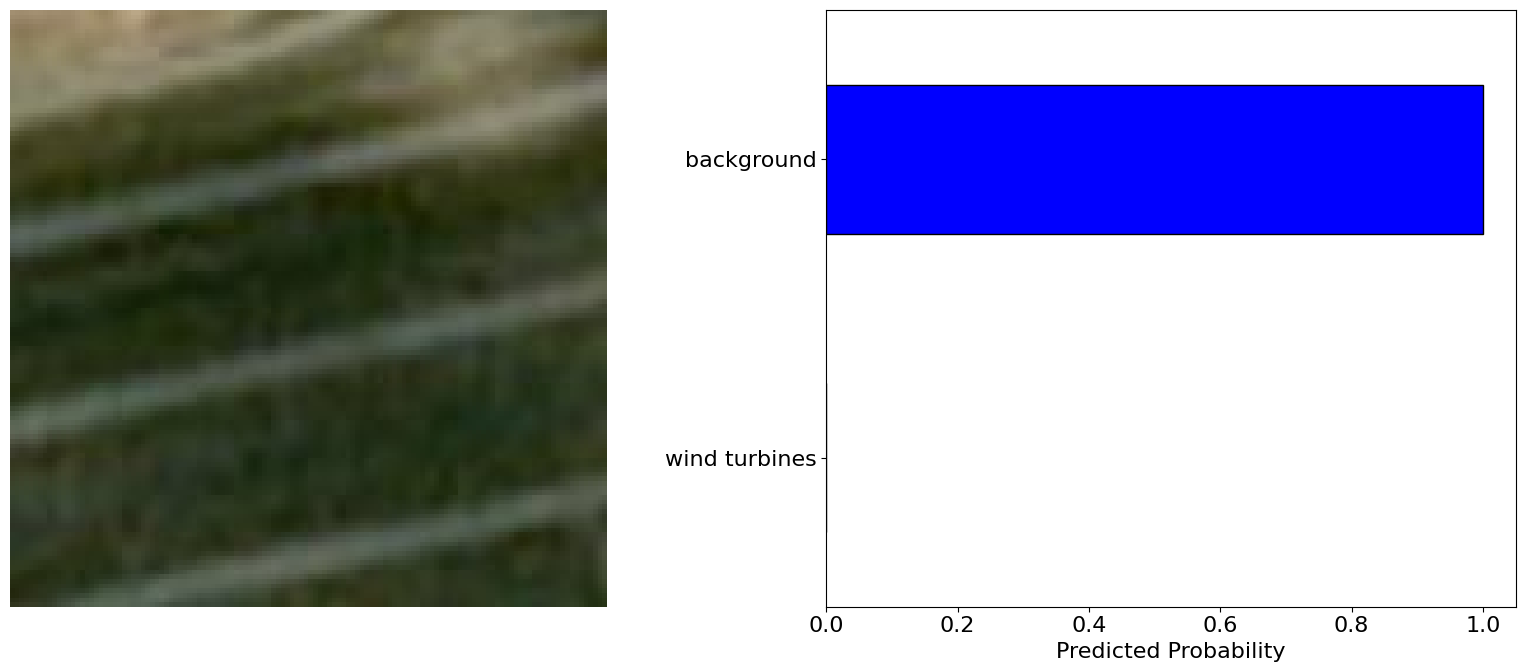

In [ ]:
labels = ["background","wind turbines"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/wind_turbines/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/wind_turbines/val/target/00a0c631-fed5-457b-916e-90cf9a99fdb0.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/wind_turbines/val/background/00ac998b-e48a-4c91-a64d-bc91f8a84798.jpg')
fig = model.predict_image(image, labels, transform)